# Residual U-Net denoising

Uses the working project setup in `projekt1/`. Missing checkpoints are trained in order: initial model, mixed fine-tuning, then joint training. Existing results are reused.


In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader
from IPython.display import display

ROOT = next(
    base / "projekt1" for base in (Path.cwd(), *Path.cwd().parents)
    if (base / "projekt1/src/denoising.py").is_file()
)
sys.path.insert(0, str(ROOT))
os.environ["TORCH_HOME"] = str(ROOT / ".cache/torch")

from src.models import MODEL_ARCHITECTURE, ResidualUNet
from src import denoising, joint_denoising
from src.bilateral_tuning import load_bilateral_settings, tune_bilateral

SEED = 42
denoising.seed_everything(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", ROOT, "| device:", DEVICE)
print("Python:", sys.executable)
print("Unchanged shared architecture:", MODEL_ARCHITECTURE)


Project: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1 | device: cpu
Python: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Scripts\python.exe
Unchanged shared architecture: residual_unet_v1


C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Bilateral tuning

In [2]:
split = json.loads((ROOT / "configs/shared_split.json").read_text())
training_files = [ROOT / "data/DIV2K/train_256" / name for name in split["training"]]
holdout_files = [ROOT / "data/DIV2K/train_256" / name for name in split["holdout"]]
tuning_dir = ROOT / "outputs/bilateral_tuning"
if (tuning_dir / "best_settings.json").exists() and (tuning_dir / "grid_results.csv").exists():
    bilateral_grid = pd.read_csv(tuning_dir / "grid_results.csv")
else:
    _, bilateral_grid = tune_bilateral(
        holdout_files, tuning_dir, seed=SEED,
        color_factors=(0.25, 0.5, 0.75, 1.0, 1.5),
        spatial_values=(0.5, 1.0, 2.0, 3.0),
    )

best_candidates = bilateral_grid.sort_values(
    ["sigma", "PSNR"], ascending=[True, False],
).groupby("sigma").head(3)
display(best_candidates.round(5))


,sigma,sigma_color,sigma_spatial,mode,images,PSNR,SSIM,initial_settings
7,0.01,0.0050,3.0,reflect,80,40.79376,0.98656,False
3,0.01,0.0025,3.0,reflect,80,40.75697,0.98177,False
2,0.01,0.0025,2.0,reflect,80,40.65858,0.98171,False
28,0.03,0.0150,3.0,reflect,80,33.40746,0.93368,False
27,0.03,0.0150,2.0,reflect,80,33.18029,0.93149,False
32,0.03,0.0225,3.0,reflect,80,32.50234,0.93160,False


In [2]:
BILATERAL_SETTINGS = load_bilateral_settings(
    tuning_dir / "best_settings.json", holdout_files, seed=SEED,
)
print("Training:", len(training_files), "| internal tuning:", len(holdout_files))
print("Frozen bilateral parameters:", BILATERAL_SETTINGS)
print("The 100 reserved images are not read for training or checkpoint selection.")


Training: 720 | internal tuning: 80
Frozen bilateral parameters: {0.01: {'sigma_color': 0.005, 'sigma_spatial': 3.0, 'mode': 'reflect'}, 0.03: {'sigma_color': 0.015, 'sigma_spatial': 3.0, 'mode': 'reflect'}}
The 100 reserved images are not read for training or checkpoint selection.


## Initial training (20 + 30 epochs)

unet_mixed_256_v1


,epoch,train_mse,validation_mse
15,16,0.000208,0.000217
16,17,0.000207,0.000215
17,18,0.000208,0.000230
18,19,0.000204,0.000214
19,20,0.000204,0.000212


unet_mixed_256_v2_lr1e4


,epoch,train_mse,validation_mse,learning_rate
25,26,0.000191,0.000204,0.0001
26,27,0.000196,0.000205,0.0001
27,28,0.000192,0.000204,0.0001
28,29,0.000205,0.000204,0.0001
29,30,0.000192,0.000204,0.0001


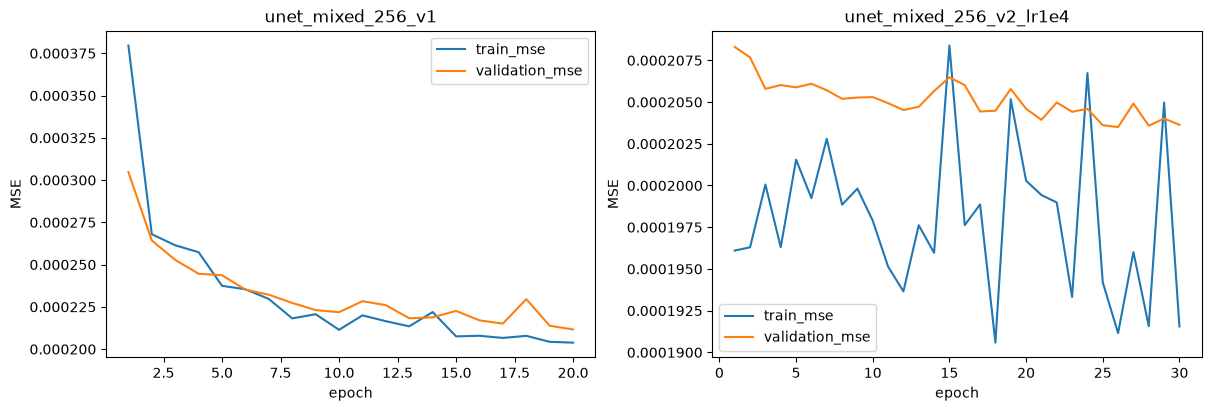

In [2]:
stages = [
    ("unet_mixed_256_v1", 20, 1e-3, None),
    ("unet_mixed_256_v2_lr1e4", 30, 1e-4,
     ROOT / "outputs/unet_mixed_256_v1/best.pt"),
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (name, epochs, learning_rate, initial_checkpoint) in zip(axes, stages):
    stage_dir = ROOT / "outputs" / name
    if (stage_dir / "best.pt").exists():
        stage_history = pd.read_csv(stage_dir / "history.csv")
    else:
        denoising.seed_everything(SEED)
        stage_config = denoising.TrainConfig(
            epochs=epochs, learning_rate=learning_rate, batch_size=2, seed=SEED,
            lr_scheduler_patience=5 if initial_checkpoint is not None else None,
        )
        stage_generator = torch.Generator().manual_seed(SEED)
        stage_train_loader = DataLoader(
            denoising.DenoisingDataset(training_files, training=True, seed=SEED),
            batch_size=2, shuffle=True, generator=stage_generator,
        )
        stage_holdout_loader = DataLoader(
            denoising.DenoisingDataset(holdout_files, training=False, seed=SEED),
            batch_size=2,
        )
        stage_model = ResidualUNet().to(DEVICE)
        stage_history = denoising.fit(
            stage_model, stage_train_loader, stage_holdout_loader, DEVICE,
            stage_config, stage_dir, initial_checkpoint=initial_checkpoint,
            split_files={"training": training_files, "holdout": holdout_files},
        )
    print(name)
    display(stage_history.tail())
    stage_history.plot(x="epoch", y=["train_mse", "validation_mse"], ax=ax, title=name)
    ax.set_ylabel("MSE")
plt.show()


## Configuration


In [11]:
RUN_DIR = ROOT / "outputs/unet_joint_balanced_v5"
PARENT_CHECKPOINT = ROOT / "outputs/unet_mixed_256_v2_lr1e4/best.pt"
config = joint_denoising.JointTrainConfig(
    epochs=30, learning_rate=1e-4, batch_size=2, seed=SEED,
)
print(config)
print("Parent:", PARENT_CHECKPOINT)
print("New output:", RUN_DIR)


JointTrainConfig(epochs=30, learning_rate=0.0001, batch_size=2, seed=42, architecture='residual_unet_v1', sigmas=(0.01, 0.03), run_kind='full', loss='mean_over_sigmas(MSE(raw_restored, clean) / sigma**2)', lr_scheduler_patience=5, lr_scheduler_factor=0.5, min_learning_rate=1e-06)
Parent: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\outputs\unet_mixed_256_v2_lr1e4\best.pt
New output: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\outputs\unet_joint_balanced_v5


In [12]:
training_dataset = joint_denoising.PairedNoiseDataset(training_files, training=True, seed=SEED)
holdout_dataset = joint_denoising.PairedNoiseDataset(holdout_files, training=False, seed=SEED)
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    training_dataset, batch_size=config.batch_size, shuffle=True, generator=loader_generator,
)
holdout_loader = DataLoader(holdout_dataset, batch_size=config.batch_size)
print("Every epoch: 720 clean targets, 1440 noisy training versions.")
print("Validation: 80 clean targets, 160 fixed noisy versions.")
print("Each forward call remains [B, 3, 256, 256] -> [B, 3, 256, 256].")


Every epoch: 720 clean targets, 1440 noisy training versions.
Validation: 80 clean targets, 160 fixed noisy versions.
Each forward call remains [B, 3, 256, 256] -> [B, 3, 256, 256].


In [13]:
reference_dir = PARENT_CHECKPOINT.parent / "holdout_tuned_bilateral"
if not (reference_dir / "summary_metrics.csv").exists():
    parent_model, _ = denoising.load_checkpoint(PARENT_CHECKPOINT, DEVICE)
    denoising.evaluate_dataset(
        holdout_files, parent_model, DEVICE, BILATERAL_SETTINGS, reference_dir,
        perceptual_metric=denoising.LPIPSMetric(DEVICE), seed=SEED, sigmas=(0.01, 0.03),
    )
reference = pd.read_csv(reference_dir / "summary_metrics.csv")
reference["method"] = reference.method.replace({"residual U-Net": "Mixed v2: starting weights"})
print("STARTING REFERENCE ONLY: same 80 tuning images, not the new joint model")
display(reference.round(5))


STARTING REFERENCE ONLY: same 80 tuning images, not the new joint model


,method,sigma,images,PSNR,SSIM,LPIPS
0,bilateral,0.01,80,40.79376,0.98656,0.00534
1,bilateral,0.03,80,33.40746,0.93368,0.03835
2,noisy input,0.01,80,40.05301,0.97306,0.00778
3,noisy input,0.03,80,30.58213,0.83963,0.06780
4,Mixed v2: starting weights,0.01,80,40.66624,0.98562,0.00769
5,Mixed v2: starting weights,0.03,80,35.20603,0.95489,0.02417


## Training


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


frozen bilateral reference: 100%|██████████| 80/80 [01:00<00:00,  1.32it/s]


Validating the parent at epoch 0; its weights remain available if this trial worsens.


Epoch 0: worst PSNR margin=-0.1275 dB; all six metric comparisons won=False


... (27 outputs left out)

Epoch 28/30: balanced train=0.49788, validation=0.51518, lr=0.0001; worst PSNR margin=+0.8020 dB; all six won=False
  sigma=0.01: PSNR=42.46041, SSIM=0.99038, LPIPS=0.00283
  sigma=0.03: PSNR=34.20946, SSIM=0.93714, LPIPS=0.03984
  Estimated remaining training/validation: 7.3 minutes


Epoch 29/30: balanced train=0.49782, validation=0.51441, lr=0.0001; worst PSNR margin=+0.7563 dB; all six won=False
  sigma=0.01: PSNR=42.50029, SSIM=0.99041, LPIPS=0.00278
  sigma=0.03: PSNR=34.16379, SSIM=0.93653, LPIPS=0.04016
  Estimated remaining training/validation: 3.7 minutes


Epoch 30/30: balanced train=0.49711, validation=0.51467, lr=0.0001; worst PSNR margin=+0.7590 dB; all six won=False
  sigma=0.01: PSNR=42.49301, SSIM=0.99046, LPIPS=0.00284
  sigma=0.03: PSNR=34.16646, SSIM=0.93663, LPIPS=0.03954
  Estimated remaining training/validation: 0.0 minutes


,epoch,learning_rate,train_balanced_loss,validation_balanced_loss,train_mse_sigma001,train_mse_sigma003,validation_mse_sigma001,validation_mse_sigma003,worst_psnr_margin_db,beats_bilateral_all_metrics_both_sigmas,epoch_seconds
25,26,0.0001,0.499224,0.516257,0.000057,0.000384,0.000059,0.000396,0.707937,False,228.764644
26,27,0.0001,0.498386,0.520093,0.000057,0.000384,0.000062,0.000379,0.912408,True,226.023251
27,28,0.0001,0.497878,0.515177,0.000057,0.000383,0.000060,0.000388,0.802005,False,225.668932
28,29,0.0001,0.497824,0.514408,0.000057,0.000383,0.000059,0.000392,0.756337,False,226.868426
29,30,0.0001,0.497109,0.514675,0.000057,0.000382,0.000059,0.000392,0.759003,False,226.364603


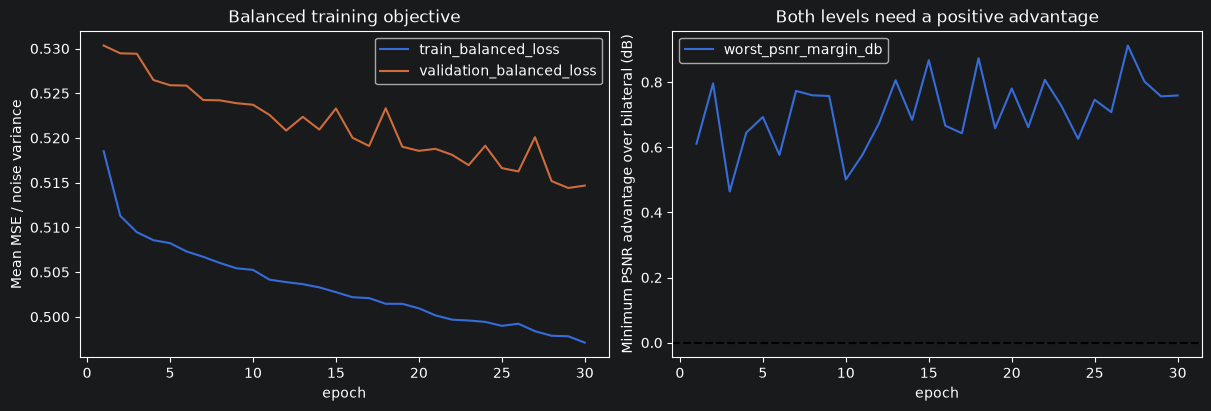

In [14]:
# Load the completed run, or train once when using a new output folder.
if (RUN_DIR / "history.csv").exists():
    history = pd.read_csv(RUN_DIR / "history.csv")
else:
    denoising.seed_everything(SEED)
    loader_generator.manual_seed(SEED)
    model = ResidualUNet().to(DEVICE)
    history = joint_denoising.fit_joint(
        model, train_loader, holdout_loader, DEVICE, config, RUN_DIR,
        initial_checkpoint=PARENT_CHECKPOINT,
        bilateral_settings=BILATERAL_SETTINGS,
        perceptual_metric=denoising.LPIPSMetric(DEVICE),
    )
display(history.tail())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
history.plot(x="epoch", y=["train_balanced_loss", "validation_balanced_loss"], ax=axes[0])
axes[0].set_ylabel("Mean MSE / noise variance")
axes[0].set_title("Balanced training objective")
history.plot(x="epoch", y="worst_psnr_margin_db", ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Minimum PSNR advantage over bilateral (dB)")
axes[1].set_title("Both levels need a positive advantage")
plt.show()


In [15]:
JOINT_CHECKPOINT = RUN_DIR / "best.pt"
joint_model, joint_checkpoint = denoising.load_checkpoint(JOINT_CHECKPOINT, DEVICE)
parent_model, _ = denoising.load_checkpoint(PARENT_CHECKPOINT, DEVICE)
print("ONE CHECKPOINT, BOTH NOISE LEVELS:", JOINT_CHECKPOINT)
print("Selected additional epoch:", joint_checkpoint["epoch"])
print("Balanced validation loss:", joint_checkpoint["validation_balanced_loss"])
print("Beats bilateral on all 3 mean metrics at BOTH levels:",
      joint_checkpoint["selection"]["beats_bilateral_all_metrics_both_sigmas"])
selected_metrics = pd.DataFrame([
    {"sigma": float(sigma), **metrics}
    for sigma, metrics in joint_checkpoint["validation_by_sigma"].items()
])
display(selected_metrics.round(6))


ONE CHECKPOINT, BOTH NOISE LEVELS: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\outputs\unet_joint_balanced_v5\best.pt
Selected additional epoch: 27
Balanced validation loss: 0.5200927884819369
Beats bilateral on all 3 mean metrics at BOTH levels: True


,sigma,images,MSE,PSNR,SSIM,LPIPS
0,0.01,80,0.000062,42.321614,0.989901,0.003185
1,0.03,80,0.000379,34.319865,0.939219,0.037846


## Holdout comparison (80 images)


In [16]:
comparison_dir = RUN_DIR / "comparison_both_sigmas_holdout"
if (comparison_dir / "summary_metrics.csv").exists():
    comparison_summary = pd.read_csv(comparison_dir / "summary_metrics.csv")
else:
    metric = denoising.LPIPSMetric(DEVICE)
    parent_rows, _ = denoising.evaluate_dataset(
        holdout_files, parent_model, DEVICE, BILATERAL_SETTINGS, comparison_dir / "parent",
        perceptual_metric=metric, seed=SEED, sigmas=(0.01, 0.03),
    )
    joint_rows, _ = denoising.evaluate_dataset(
        holdout_files, joint_model, DEVICE, BILATERAL_SETTINGS, comparison_dir / "joint",
        perceptual_metric=metric, seed=SEED, sigmas=(0.01, 0.03),
    )
    parent_rows["method"] = parent_rows.method.replace({"residual U-Net": "Mixed v2 (parent)"})
    joint_only = joint_rows[joint_rows.method == "residual U-Net"].copy()
    joint_only["method"] = "Joint balanced U-Net (one checkpoint)"
    comparison_rows = pd.concat([parent_rows, joint_only], ignore_index=True)
    comparison_summary = comparison_rows.groupby(["method", "sigma"], as_index=False).agg(
        images=("image", "count"), PSNR=("PSNR", "mean"),
        SSIM=("SSIM", "mean"), LPIPS=("LPIPS", "mean"),
    )
    comparison_rows.to_csv(comparison_dir / "per_image_metrics.csv", index=False)
    comparison_summary.to_csv(comparison_dir / "summary_metrics.csv", index=False)

display(comparison_summary.sort_values(["sigma", "method"]).round(5))
decisions = []
for sigma in (0.01, 0.03):
    group = comparison_summary[comparison_summary.sigma == sigma].set_index("method")
    network = group.loc["Joint balanced U-Net (one checkpoint)"]
    baseline = group.loc["bilateral"]
    decisions.append({
        "sigma": sigma,
        "PSNR gain (dB)": network.PSNR - baseline.PSNR,
        "SSIM gain": network.SSIM - baseline.SSIM,
        "LPIPS reduction": baseline.LPIPS - network.LPIPS,
        "beats all 3 mean metrics": bool(
            network.PSNR > baseline.PSNR and network.SSIM > baseline.SSIM
            and network.LPIPS < baseline.LPIPS
        ),
    })
decision_table = pd.DataFrame(decisions)
display(decision_table.round(6))
print("ONE MODEL BEATS BILATERAL AT BOTH LEVELS:",
      bool(decision_table["beats all 3 mean metrics"].all()))
print("Saved:", comparison_dir)


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


evaluate images: 100%|██████████| 80/80 [01:27<00:00,  1.09s/it]

CURRENT CHECKPOINTS: BOTH SIGMAS, SAME 80 TUNING IMAGES


,method,sigma,images,PSNR,SSIM,LPIPS
0,Joint balanced U-Net (one checkpoint),0.01,80,42.32161,0.98990,0.00318
2,Mixed v2 (parent),0.01,80,40.66624,0.98562,0.00769
4,bilateral,0.01,80,40.79376,0.98656,0.00534
6,noisy input,0.01,80,40.05301,0.97306,0.00778
1,Joint balanced U-Net (one checkpoint),0.03,80,34.31987,0.93922,0.03785
3,Mixed v2 (parent),0.03,80,35.20603,0.95489,0.02417
5,bilateral,0.03,80,33.40746,0.93368,0.03835
7,noisy input,0.03,80,30.58213,0.83963,0.06780


,sigma,PSNR gain (dB),SSIM gain,LPIPS reduction,beats all 3 mean metrics
0,0.01,1.527856,0.003337,0.002158,True
1,0.03,0.912408,0.005537,0.000505,True


ONE MODEL BEATS BILATERAL AT BOTH LEVELS: True
Saved: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\outputs\unet_joint_balanced_v5\comparison_both_sigmas_holdout


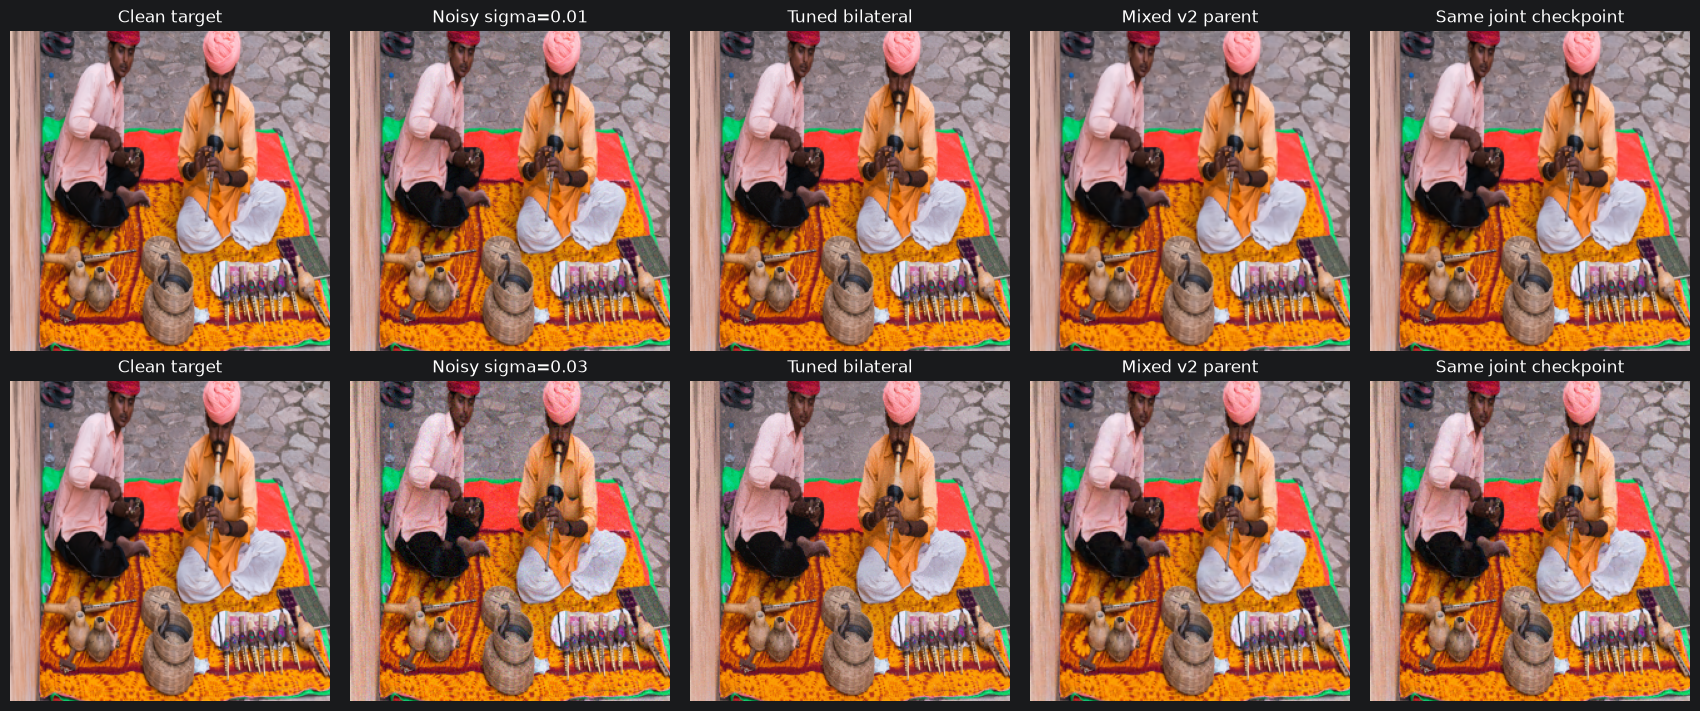

In [17]:
path = holdout_files[0]
clean = denoising.read_rgb(path)
fig, axes = plt.subplots(2, 5, figsize=(17, 7), constrained_layout=True)
for row, sigma in enumerate((0.01, 0.03)):
    noisy = denoising.add_gaussian_noise(clean, sigma, denoising.evaluation_seed(path, sigma, SEED))
    panels = [
        (clean, "Clean target"),
        (noisy, f"Noisy sigma={sigma}"),
        (denoising.bilateral_rgb(noisy, **BILATERAL_SETTINGS[sigma]), "Tuned bilateral"),
        (denoising.predict_rgb(parent_model, noisy, DEVICE), "Mixed v2 parent"),
        (denoising.predict_rgb(joint_model, noisy, DEVICE), "Same joint checkpoint"),
    ]
    for ax, (image, title) in zip(axes[row], panels):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
plt.show()


## Final evaluation (100 images)


In [19]:
final_files = [ROOT / "data/DIV2K/valid_256" / name
               for name in split["final_evaluation_public_validation"]]
final_dir = RUN_DIR / "evaluation_div2k_public_valid_both_sigmas"
if (final_dir / "summary_metrics.csv").exists():
    final_summary = pd.read_csv(final_dir / "summary_metrics.csv")
else:
    final_rows, final_summary = denoising.evaluate_dataset(
        final_files, joint_model, DEVICE, BILATERAL_SETTINGS, final_dir,
        perceptual_metric=denoising.LPIPSMetric(DEVICE), seed=SEED, sigmas=(0.01, 0.03),
    )
    # Save the evaluated checkpoint so report tables can be traced back to it.
    metadata_path = final_dir / "evaluation_config.json"
    metadata = json.loads(metadata_path.read_text())
    metadata.update(
        checkpoint=str(JOINT_CHECKPOINT.resolve()), checkpoint_epoch=joint_checkpoint["epoch"],
        checkpoint_sha256=hashlib.sha256(JOINT_CHECKPOINT.read_bytes()).hexdigest(),
        split="100 reserved public DIV2K validation images; final-evaluation proxy, not official test",
    )
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("FINAL EVALUATION: ONE CHECKPOINT, BOTH SIGMAS, 100 RESERVED IMAGES")
display(final_summary.sort_values(["sigma", "method"]).round(5))
print("Saved:", final_dir)


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


evaluate images: 100%|██████████| 100/100 [01:29<00:00,  1.12it/s]

FINAL EVALUATION: ONE CHECKPOINT, BOTH SIGMAS, 100 RESERVED IMAGES


,method,sigma,images,PSNR,SSIM,LPIPS
0,bilateral,0.01,100,40.92667,0.98645,0.00566
2,noisy input,0.01,100,40.07459,0.97222,0.00877
4,residual U-Net,0.01,100,42.55759,0.99047,0.00305
1,bilateral,0.03,100,33.53470,0.93368,0.03819
3,noisy input,0.03,100,30.59984,0.83740,0.06936
5,residual U-Net,0.03,100,34.36888,0.93792,0.03987


Saved: C:\Users\Ola\Desktop\uczelniane\sem2\sigk\projekt1\outputs\unet_joint_balanced_v5\evaluation_div2k_public_valid_both_sigmas
